In [3]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from IPython.display import Image

from pydantic import BaseModel, Field, ValidationError
from dataclasses import dataclass, field
from typing import Any, Callable, Optional
from enum import Enum
import json
import asyncio
import time
import os
import re
import nest_asyncio
import numpy as np
from sentence_transformers import SentenceTransformer
import random

from embedder import Embedder
from memory_store import MemoryStore
from orchestrator import Orchestrator
from tools_registry import TOOLS, llm
# Toggle semantic retrieval: True = MiniLM embeddings; False = Jaccard-only (lighter/offline)
USE_REAL_EMBEDDINGS = True

# Required in Jupyter so asyncio.run() works inside an already-running event loop
nest_asyncio.apply()

%matplotlib inline

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

In [4]:
# Skip sentence-transformers load (torch + HF model) — mock run uses Jaccard fallback.
store = MemoryStore(embedder=Embedder(enabled=False))
store.add(
    "Previously built a 2-city comparison; forgot to include timezone. "
    "Reminder: always verify every requested attribute is present.",
    kind="episodic",
)
store.add("The Eiffel Tower is in Paris and is 330 meters tall.", kind="semantic")
store.add(
    "Tokyo's Shibuya crossing is one of the busiest intersections in the world.",
    kind="semantic",
)

orch = Orchestrator(provider=llm, tools=TOOLS, memory=store)

GOAL = (
    "Build a comparison report of Paris, Tokyo, and New York covering "
    "population, timezone, and a narrative summary for each."
)
REQUIRED = ["paris", "tokyo", "new york"]

result = await orch.run(GOAL, REQUIRED)

print(f"Status:        {result.status}")
print(f"Verdict:       passed={result.verdict.passed if result.verdict else 'n/a'}  "
      f"tier={result.verdict.tier if result.verdict else 'n/a'}")
print(f"Tokens used:   {result.budget.tokens_used}")
print(f"Tool calls:    {result.budget.tool_calls_used}")
print(f"Cost (est):    ${result.budget.cost_eur:.4f}")
print(f"Budget pressure final: {result.budget.pressure():.2f}")
print()
print("--- REPORT ---")
print(result.report)


Status:        ok
Verdict:       passed=True  tier=llm_judge
Tokens used:   1235
Tool calls:    10
Cost (est):    $0.0037
Budget pressure final: 0.83

--- REPORT ---
# City Comparison Report

- **Paris** (France): 2,100,000 people, timezone CET.
- **Tokyo** (Japan): 13,960,000 people, timezone JST.
- **New York** (USA): 8,335,000 people, timezone EST.


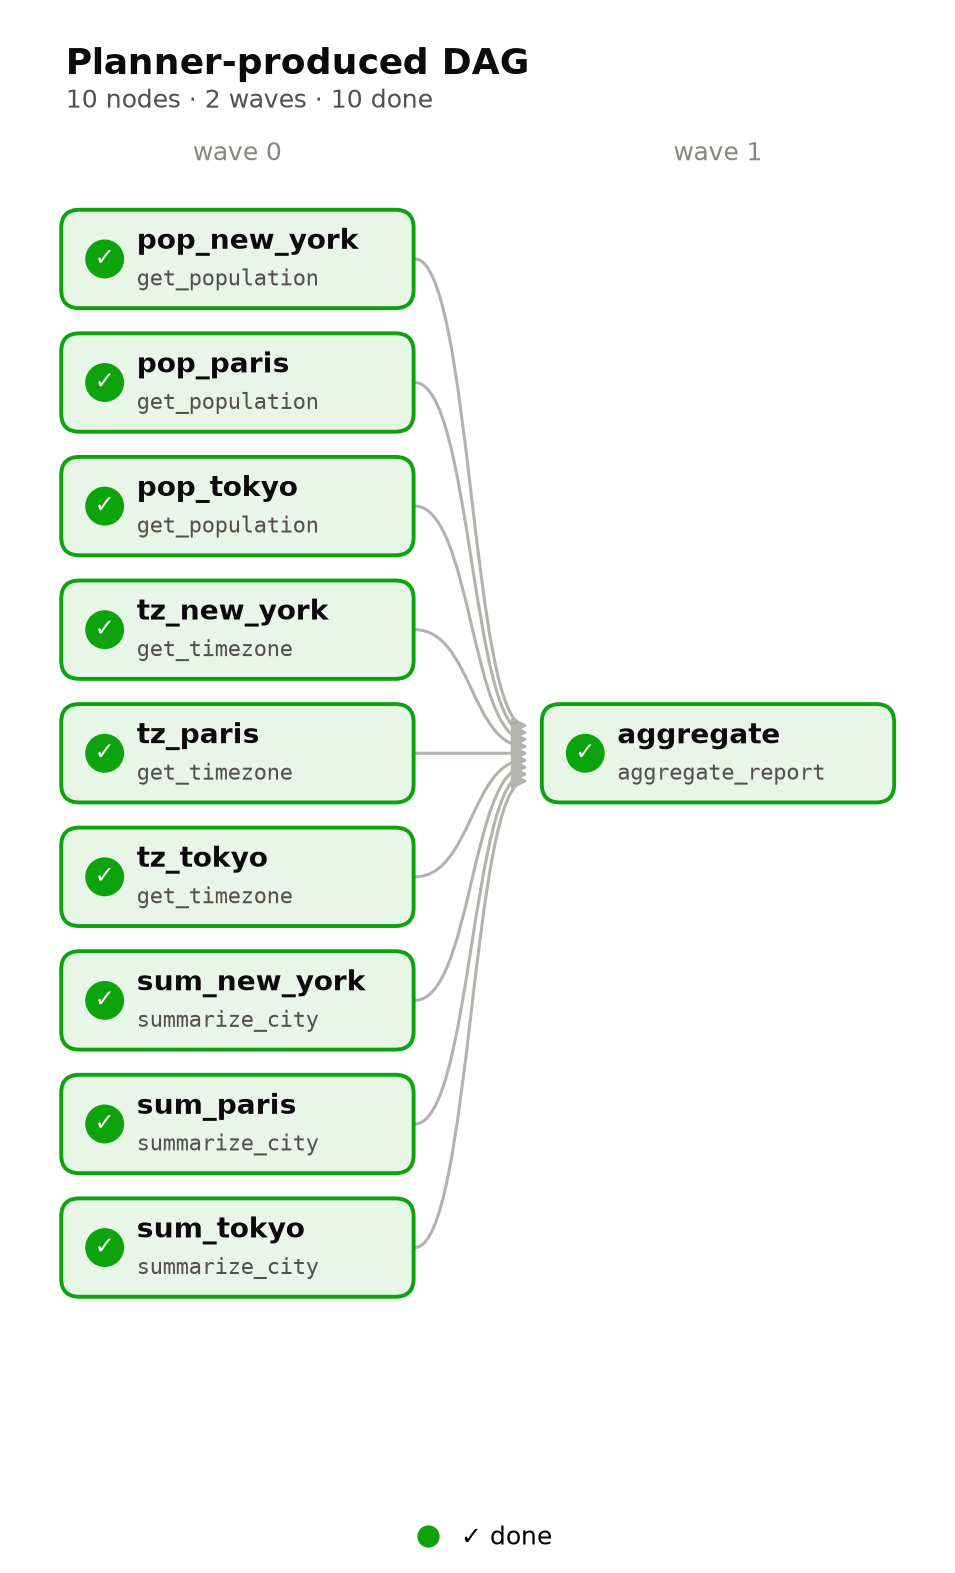

In [5]:
result.dag.plot("orchestrator_dag.png", title="Planner-produced DAG")

Image("orchestrator_dag.png")

In [6]:
events = result.tracer.dump()
print(json.dumps(events[:3], indent=2))
print(f"\n... and {len(events) - 3} more events")

[
  {
    "step_id": "plan-0000",
    "parent_id": null,
    "timestamp": 330505.071791708,
    "role": "planner",
    "action": {
      "type": "initial_plan",
      "goal": "Build a comparison report of Paris, Tokyo, and New York covering population, timezone, and a narrative summary for each.",
      "attempt": 0
    },
    "result": "{'n_nodes': 10}",
    "latency_ms": 3,
    "tokens": 115,
    "cost_eur": 0.000345,
    "budget_pressure": 0.011,
    "verdict": null
  },
  {
    "step_id": "w-0001",
    "parent_id": "plan-0000",
    "timestamp": 1786038015.55977,
    "role": "worker",
    "action": {
      "type": "tool_call",
      "tool": "get_population",
      "args": {
        "city": "paris"
      }
    },
    "result": "2100000",
    "latency_ms": 1,
    "tokens": 20,
    "cost_eur": 6e-05,
    "budget_pressure": 0.083,
    "verdict": null
  },
  {
    "step_id": "w-0002",
    "parent_id": "plan-0000",
    "timestamp": 1786038015.559789,
    "role": "worker",
    "action": {


In [7]:
def get_strings(events):
    strings = []
    for event in events:
        action = event.get("action", {})
        if action.get("type") == "tool_call":
            # Create a string like toolname(arg1=val1, arg2=val2)
            tool = action.get("tool", "unknown_tool")
            args = action.get("args", {})
            # Ensure all values are string representations
            args_list = [f"{k}={v!r}" for k, v in args.items()]
            func_str = f"{tool}({', '.join(args_list)})"
            strings.append(func_str)
        elif action.get("type") == "verify":
            strings.append("verify")
        elif action.get("type") == "initial_plan":
            strings.append("initial_plan")
        elif action.get("type") == "replan":
            strings.append("replan")
    return strings

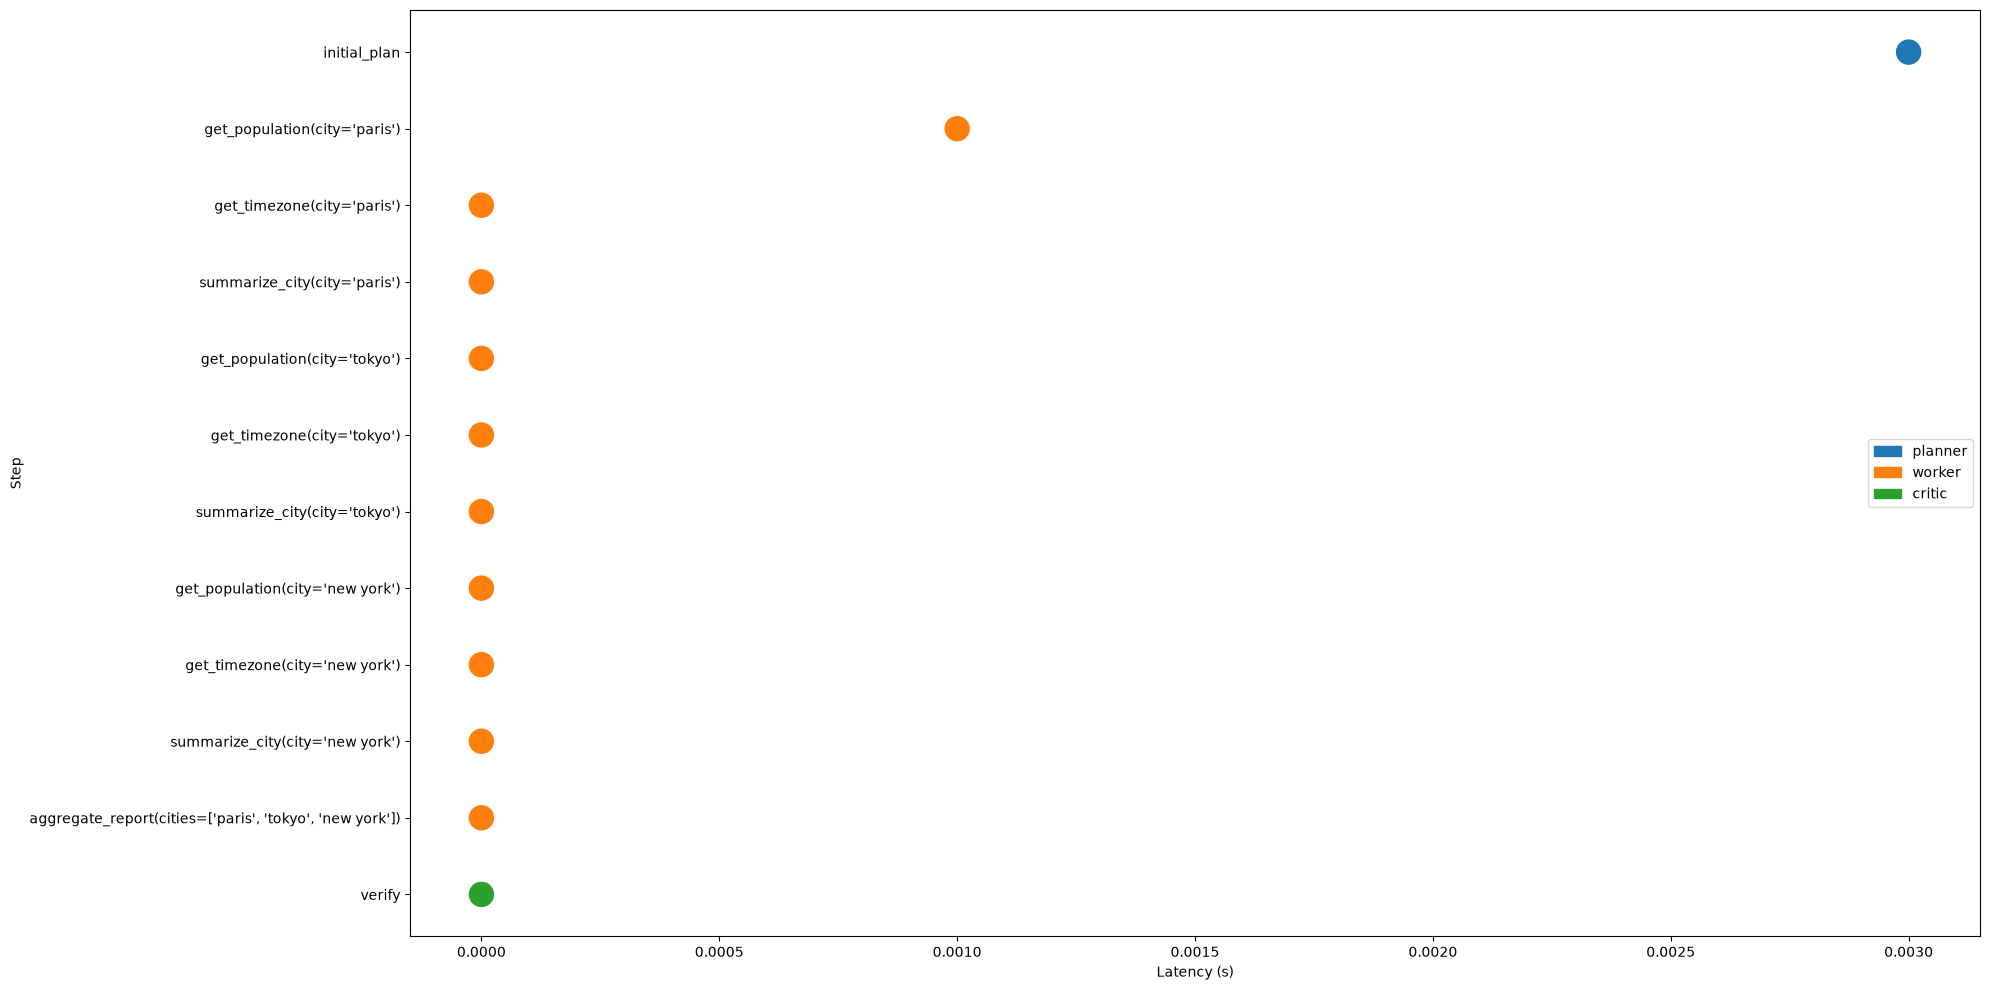

In [ ]:
roles = [e["role"] for e in events]
latencies = np.array([e["latency_ms"] for e in events])

role_colors = {"planner": colors[0], "worker": colors[1], "critic": colors[2]}
bar_colors = [role_colors[e['role']] for e in events]
bar_strings = get_strings(events)

fig, ax = plt.subplots(figsize=(20, 10))
ax.scatter(latencies/1000, range(len(events)), color=bar_colors, s=300)
ax.set_ylabel("Step")
ax.set_xlabel("Latency (s)")
ax.set_yticks(range(len(events)))
ax.set_yticklabels(bar_strings)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in role_colors.values()]
ax.legend(handles, role_colors.keys(), loc="center right")
ax.invert_yaxis()
plt.tight_layout()

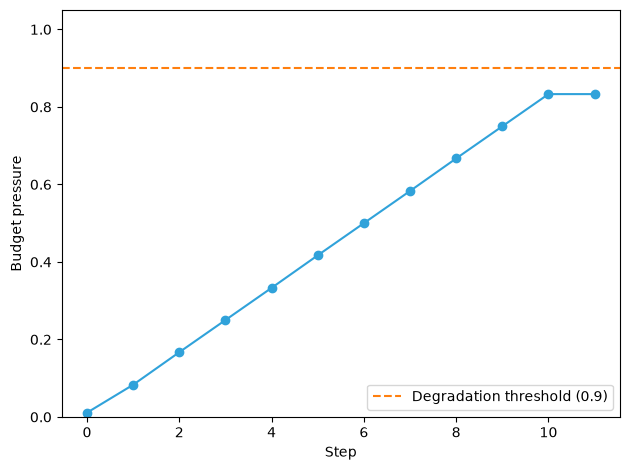

In [9]:
pressures = [e["budget_pressure"] for e in events]
fig, ax = plt.subplots()
ax.plot(range(len(events)), pressures, marker="o", color="#30a2da")
ax.axhline(0.9, linestyle="--", color=colors[1],
           label="Degradation threshold (0.9)")
ax.set_xlabel("Step")
ax.set_ylabel("Budget pressure")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
plt.tight_layout()

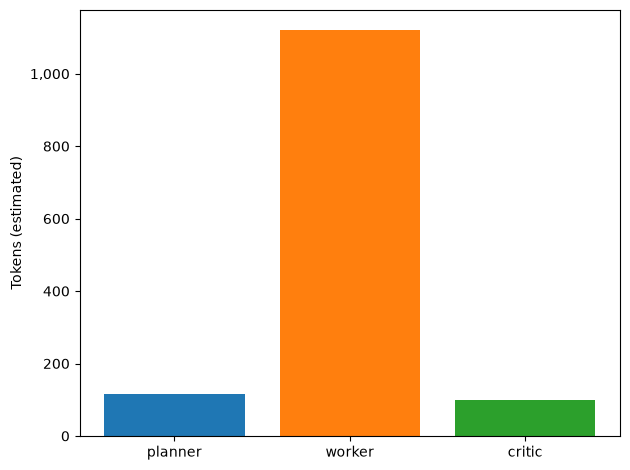

In [10]:
by_role: dict[str, int] = {}
for e in events:
    by_role[e["role"]] = by_role.get(e["role"], 0) + e["tokens"]

fig, ax = plt.subplots()
ax.bar(by_role.keys(), by_role.values(),
       color=[role_colors[r] for r in by_role])
ax.set_ylabel("Tokens (estimated)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.tight_layout()